
# EMATM0048: Software Development Programming and Algorithms (SDPA)
# `Tutorial - Web Scraping`


This section briefly summarizes the most important calls with requests. For details see the documentation (http://docs.python-requests.org/en/latest/).

### Installation
In the following you find an install procedure working within the notebook (respectively after restart). Usefull links for installing modules and managing packages can be found here:

- Python Setup Tools (https://pypi.python.org/pypi/setuptools) : Software managers are easy_install or pip
- Installing Python Modules (https://docs.python.org/3.8/install/index.html) : Standard command after downloading the source python setup.py install



# Part A: APIs
In this tutorial, we will take a look at a way to gather data using API scraping. Most websites offer an API (or Application Programming Interface) as a service which provides a high level interface to directly retrieve data from their repositories or databases at the backend.

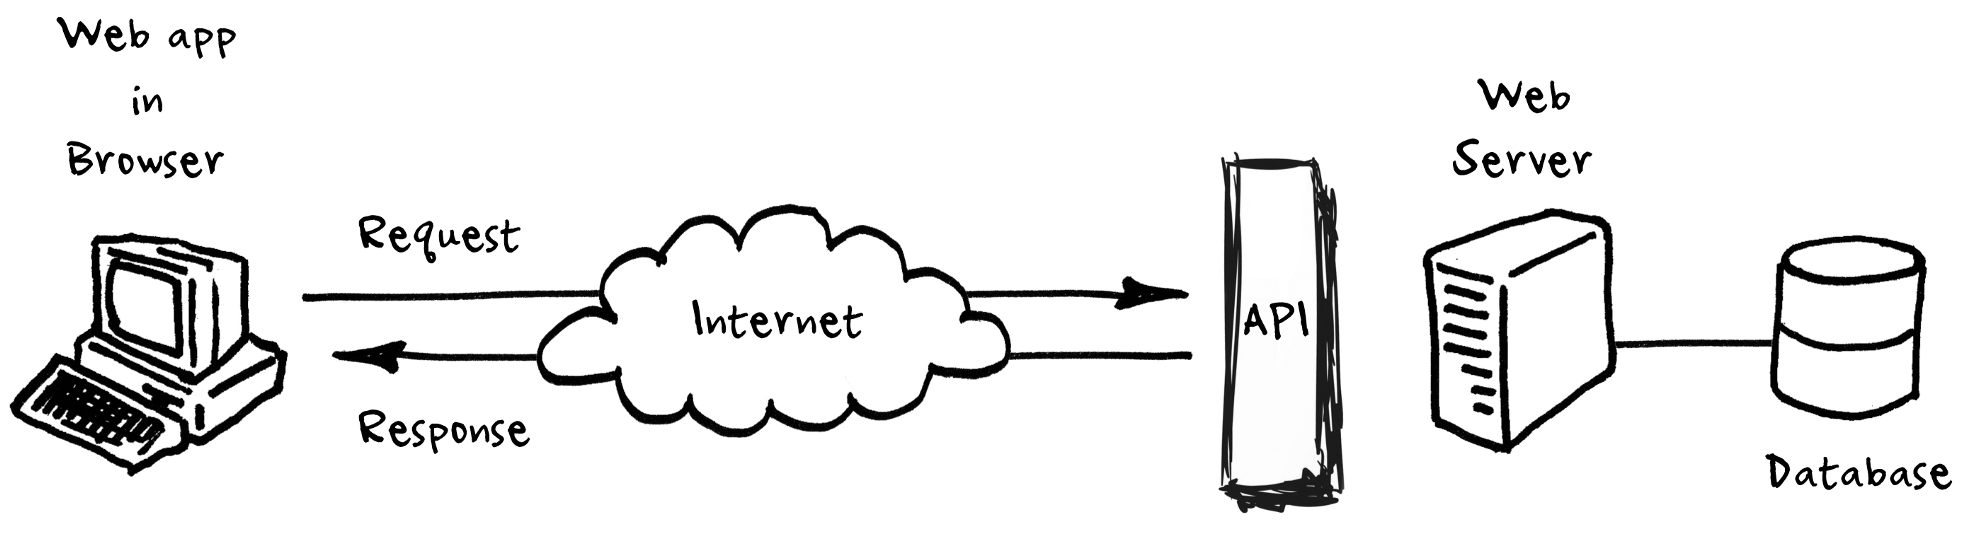

source: https://monashdatafluency.github.io/python-web-scraping/section-3-API-based-scraping/

In this tutorial we will learn about: 
* How to call APIs
* Example I: Wikipedia API
* Example II: Reddit API
* Example III: Foursquare API

## Example I: Wikipedia API

Let's say we want to gather some additional data about the university of bristol and since wikipedia is a rich source for data.  For e.g. consider the wikipedia article for university of Bristol (https://en.wikipedia.org/wiki/University_of_Bristol). 
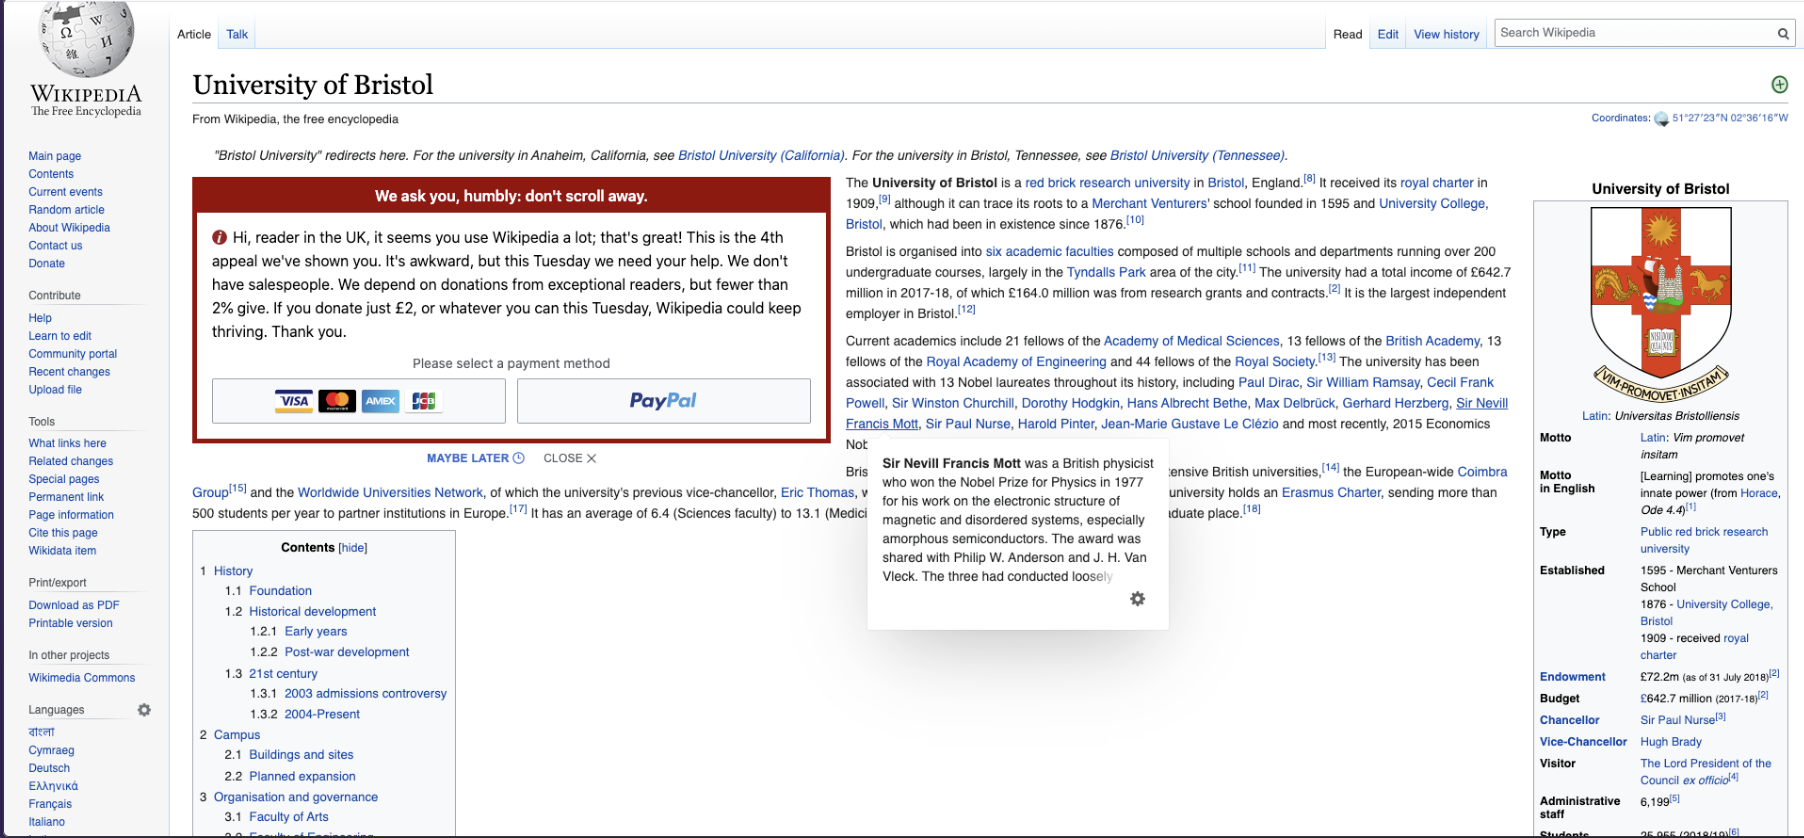
Let's begin by installing some of libraries we will use for this excercise as follows

In [8]:
# sudo apt install libcurl4-openssl-dev libssl-dev
!pip install wikipedia
!pip install wordcloud
!pip install requests

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11757 sha256=3bab034c914fcecafbdaf077763abdf6952dc43c1b0f7b6f23b81eefffe97f23
  Stored in directory: /Users/songxibo/Library/Caches/pip/wheels/30/24/d3/9d46daa49494cef2f32dc9a8f203aac1f10cec980adba03d1f
Successfully built wikipedia


In [13]:
import json
import pandas as pd
import wikipedia

wikipedia provides easy to use methods to directly call the wiki API on our behalf and get us all the wikipedia data. Let's try retrieving data for the university of Bristol as follows,

<span style="color: red;">Note that the wikipedia API is not stable so proper return of data is not guarenteed. </span>

In [11]:
print(wikipedia.search("University of Bristol"))

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

As you see in the output, the searched title along with the related search suggestions are displayed. There are some of the ways where you can filter the search results by using search parameters such as results and suggestion (I know don’t worry about the spelling). The result returns the maximum number of results and the suggestion if True, return results and suggestion (if any) in a tuple.

In [ ]:
print(wikipedia.search("University of Bristol", results=5, suggestion=True))

## Extracting Wikipedia Article Summary
We can extract the summary of a Wikipedia article using the summary() method. The article for which the summary needs to be extracted is passed as a parameter to this method.

Let's extract the summary for "University of Bristol":

In [ ]:
print(wikipedia.summary("University of Bristol"))

## Page Access
The API also gives us full access to the Wikipedia page, with the help of which we can access the title, URL, content, images, links of the complete page. In order to access the page you need to load the page first as shown below:
Just a heads up, I will use a single article topic  as a reference in this example:

In [ ]:
UoB = wikipedia.page("University of Bristol")
print(UoB.title)

In [ ]:
print(UoB.content)


In [ ]:
print(UoB.images)


In [ ]:
print(UoB.links)


-------------

# Part B: HTML based scraping



In this part we will look at a few HTML fundamentals to understand how web scraping works and scrape a website for structured data. 

We will cover the following: 
- HTTP Requests to crawl HTML page
- Reading HTML table with Pandas
- Parsing HTML page with BeautifulSoup

## 1. HTTP Requests in Python: The requests Package

Instead of the browser requesting for the content of the webpage, Python can be used for the same. A HTTP request to the web server can be sent with the requests library and the response can be examined. Typically every request receives a response with response headers and status code details.
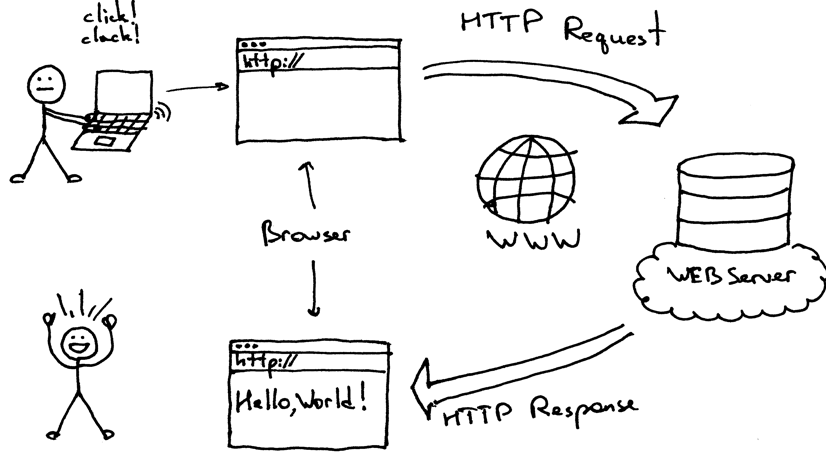
image source: https://monashdatafluency.github.io/pytho

Let us request for the web content for this web site https://api.github.com/events The requests library can be used to work with webpages and web content. A request is made to get the content of the webpage with the get() method. The requests module provides an easy and handy API to send http requests over the network.


In [1]:
!pip install requests

### Usage
A brief example (based on the requests documentation http://docs.python-requests.org/en/latest/user/quickstart/):

In [2]:
import requests
r = requests.get('https://api.github.com/events')
print ("Status of request (200=success): %d"%r.status_code)

Status of request (200=success): 200


### The request object
The request is the main source of invoking http requst. For every request method (the verbs), a separate function exist.

A response is received from the web server. This response will have response headers and status codes associated to that particular request. Response headers give the detailed information about the request made to the web server.


In [3]:
r.headers

{'Date': 'Wed, 11 Nov 2026 12:33:54 GMT', 'Content-Type': 'application/json; charset=utf-8', 'Cache-Control': 'public, max-age=300, s-maxage=300', 'Vary': 'Accept,Accept-Encoding, Accept, X-Requested-With', 'ETag': 'W/"d0e2cd49f62a6137e2f06cf4ca5812f51396de5054b161536de57a149b07b8d4"', 'Last-Modified': 'Tue, 10 Nov 2026 18:11:53 GMT', 'X-Poll-Interval': '60', 'X-GitHub-Media-Type': 'github.v3; format=json', 'Link': '<https://api.github.com/events?page=2>; rel="next", <https://api.github.com/events?page=10>; rel="last"', 'x-github-api-version-selected': '2022-11-28', 'Access-Control-Expose-Headers': 'ETag, Link, Location, Retry-After, X-GitHub-OTP, X-RateLimit-Limit, X-RateLimit-Remaining, X-RateLimit-Used, X-RateLimit-Resource, X-RateLimit-Reset, X-OAuth-Scopes, X-Accepted-OAuth-Scopes, X-Poll-Interval, X-GitHub-Media-Type, X-GitHub-SSO, X-GitHub-Request-Id, Deprecation, Sunset, Warning', 'Access-Control-Allow-Origin': '*', 'Strict-Transport-Security': 'max-age=31536000; includeSubdoma

In [4]:
print ("HTTP Headers %s"%str(r.headers['content-type']))

HTTP Headers application/json; charset=utf-8


Every response will have a status code. The status codes indicate whether a specific HTTP request has been successfully completed. Responses are grouped in five classes:

- Informational responses (100–199)
- Successful responses (200–299)
- Redirects (300–399)
- Client errors (400–499)
- Server errors (500–599)
Let us check the response status code for the HTTP request we placed



In [5]:
print ("Status of request (200=success): %d"%r.status_code)

Status of request (200=success): 200


Response automatically decode content from the server by guessing/estimating the encoding. The content can be accessed under the 'text' field. After changing the encoding through setting 'encoding' subsquent access to 'text' provides the new encoding.

In [6]:
r.text[1:1000]

'{"id":"26841944147","type":"PushEvent","actor":{"id":240237641,"login":"princecharming001","display_login":"princecharming001","gravatar_id":"","url":"https://api.github.com/users/princecharming001","avatar_url":"https://avatars.githubusercontent.com/u/240237641?"},"repo":{"id":1402269421,"name":"princecharming001/orbit","url":"https://api.github.com/repos/princecharming001/orbit"},"payload":{"repository_id":1402269421,"push_id":49587882048,"ref":"refs/heads/main","head":"fc0305605d6c26bc1fa0be280fad3e34326ab4a2","before":"de75a2903767bf4db89fd963be9e8cfbfbd31028"},"public":true,"created_at":"2026-11-09T15:31:04Z"},{"id":"26841943844","type":"PushEvent","actor":{"id":41898282,"login":"github-actions[bot]","display_login":"github-actions","gravatar_id":"","url":"https://api.github.com/users/github-actions[bot]","avatar_url":"https://avatars.githubusercontent.com/u/41898282?"},"repo":{"id":1411904954,"name":"yassineofd/intosudoku-instagram","url":"https://api.github.com/repos/yassineofd

### JSON Response Content
JSON is returned via requests.json

In [7]:
print (type(r.json()))
#pretty print the json using json.dumps
print (json.dumps(r.json(), indent =  4))

<class 'list'>


NameError: name 'json' is not defined

-----------

## 2.  Reading HTML tables with Pandas
The pandas read_html() function is a quick and convenient way to turn an HTML table into a pandas DataFrame. This function can be useful for quickly incorporating tables from various websites without figuring out how to scrape the site’s HTML. However, there can be some challenges in cleaning and formatting the data before analysing it.The basic usage is of pandas read_html is pretty simple and works well on many Wikipedia pages since the tables are not complicated.

## Example: Wikipedia

In [ ]:
import requests
import pandas as pd
from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_countries_and_dependencies_by_population"

r = requests.get(
    url,
    headers={
        "User-Agent": "PopulationTableStudy/1.0 (educational notebook)"
    },
    timeout=20
)
r.raise_for_status()

tables = pd.read_html(StringIO(r.text), flavor="lxml")
df = tables[0]

print(df.head())

To get a DataFrame from this list, you only need to make one addition:


### <font color= 'Blue'> Question: </font>

Extract cities in the UK from information in tables on this website
https://en.wikipedia.org/wiki/List_of_cities_in_the_United_Kingdom

## Parsing HTML page with BeautifulSoup: 
You might need to parse HTML for information that are not represented in tables. 


## Step 1: Send a request and get the page contents 

In [ ]:
import requests
import pandas as pd

web_url = 'https://www.luckytailsalpacafarm.co.uk/'
response = requests.get(web_url)

print('Status code\n', response.status_code)
print('\n--\n')
print('Content of the website\n', response.content[:2000])


## Step 2: Parsing HTML and accessing different elements¶


bs4 is a Python library which parses through HTML content and understands the complete structure of the content. The response content can be passed to a BeautifulSoup() method to obtain a soup object which looks very structured.

In [ ]:
! pip install bs4

In [ ]:
from bs4 import BeautifulSoup
soup_object = BeautifulSoup(response.content)

# Uncomment the below line and look into the contents of soup_object
#print(soup_object.prettify())

### Explore the schema: Manipulating elments of HTML page


To be able to accurately extract relevant data from the webpage, it is important to explore the schema and understand the structure of the webpage. A good way to do this is to inspect the webpage directly on a web browser.

This HTML content is  transformed into a BeautifulSoup object, with the following structure:

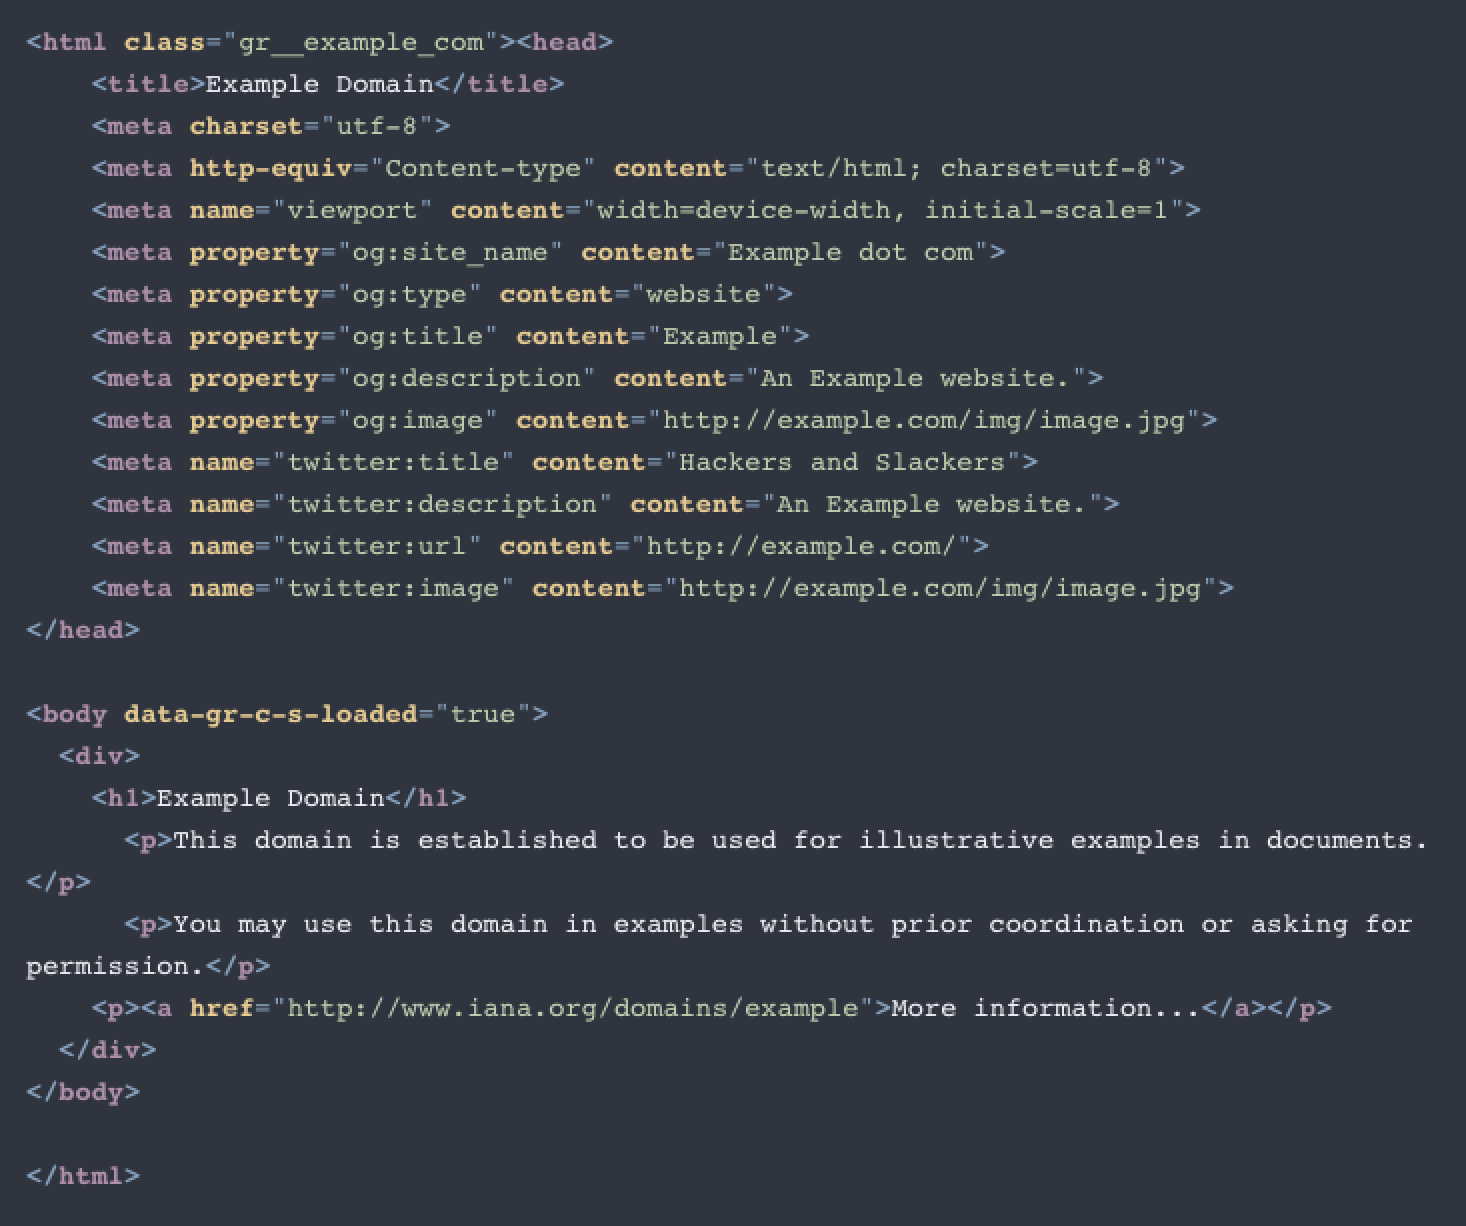

To inspect elements in th epage, open the webpage on a browser - Right click on the data content to be extracted - Click on Inspect or Inspect element option This will open a console window which shows the real time HTML code corresponding to the web content. Now identify the type of HTML tag which contains all the data along with any id names or class names associated to that HTML tag. In our case, the data is enclosed in the \<table> HTML tag with the class name 'data-table'. This information can be used to search for the web content directly in our soup object with the find_all() method. This will return a soup object.

If you are not familiar with HTML, take some time to read about HTML element tags, HTML element attributes and HTML classes. Knowing about these parts of HTML will make it much easier for us to identify and extract the data we want. Let's first what is inside the soup object as a text




In [ ]:
## Uncomment this to see the contents
print(soup_object.get_text())

There are a lot of blank lines in this output. These are the result of newline characters in the HTML document’s text. 

The most straightforward way to finding information in our soup variable is by utilizing soup.find(...) or soup.find_all(...). These two methods work the same with one exception: find returns the first HTML element found, whereas find_all returns a list of all elements matching the criteria (even if only one element is found, find_all will return a list of a single item).


- Often, you need to get only specific text from an HTML document. Using Beautiful Soup first to extract the text and then using the .find() string method is sometimes easier than working with regular expressions.

- However, sometimes the HTML tags themselves are the elements that point out the data you want to retrieve. For instance, perhaps you want to retrieve the URLs for all the images on the page. These links are contained in the src attribute of \<img> HTML tags. In this case, you can use find_all() to return a list of all instances of that particular tag

In [ ]:
#find a tag
soup_object.find_all("img")

This returns a list of all \<img> tags in the HTML document. The objects in the list look like they might be strings representing the tags, but they’re actually instances of the Tag object provided by Beautiful Soup. Tag objects provide a simple interface for working with the information they contain.

Let’s explore this a little by first unpacking the Tag objects from the list:

In [ ]:
image1 = soup_object.find_all("img")[0]

Each Tag object has a .name property that returns a string containing the HTML tag type.ou can access the HTML attributes of the Tag object by putting their name between square brackets, just as if the attributes were keys in a dictionary.

For example, the \<img src="/static/dionysus.jpg"/> tag has a single attribute, src, with the value "/static/dionysus.jpg". Likewise, an HTML tag such as the link \<a href="https://realpython.com" target="_blank"> has two attributes, href and target.

To get the source of the images in the Dionysus profile page, you access the src attribute using the dictionary notation mentioned above:


In [ ]:
image1["src"]

## <font color= "blue">Question:</font>
- Extract "Leave a Reply" title from this article
-  Extract all links on the page

### References: 
- https://pbpython.com/pandas-html-table.html
- https://monashdatafluency.github.io/python-web-scraping/section-2-HTML-based-scraping/
- https://towardsdatascience.com/2-easy-ways-to-get-tables-from-a-website-with-pandas-b92fc835e741
- For some of you who are interested in Earth data analytics
https://www.earthdatascience.org/courses/use-data-open-source-python/
- https://monashdatafluency.github.io/python-web-scraping/section-3-API-based-scraping/
- List of public APIs https://github.com/public-apis/public-apis
- More on FourSquare API https://gist.github.com/doscsy12/7457716c264249c8a8ef19a053dd9605